## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
import numpy as np

## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

In [2]:
data = pd.read_csv("https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1")

X = data[["age", "chol"]]
y = (data["diagnosis"] == "Disease").astype(int)

logmod = LogisticRegression(max_iter=1000)
logmod.fit(X, y)

# Extract coefficients
b0 = logmod.intercept_[0]
b_age = logmod.coef_[0][0]
b_chol = logmod.coef_[0][1]

# Assume 50% threshold

chol_50 = (-b0 - 55*b_age) / b_chol
print("Cholesterol for 50% probability:", chol_50)

# Solve for level with 90% prob

chol_90 = (np.log(9) - b0 - 55*b_age) / b_chol
print("Cholesterol for 90% probability:", chol_90)

Cholesterol for 50% probability: 367.87488979860143
Cholesterol for 90% probability: -851.9660996781224


In [3]:
test_patients = pd.DataFrame({
    "age": [55, 55],
    "chol": [chol_50, chol_90]
})

logmod.predict_proba(test_patients)

array([[0.5, 0.5],
       [0.1, 0.9]])

## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [4]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [5]:
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

b0_lda = lda.intercept_[0]
b_age_lda = lda.coef_[0][0]
b_chol_lda = lda.coef_[0][1]

age = 55

chol_lda = (-b0_lda - b_age_lda * age) / b_chol_lda
print(f"LDA cholesterol threshold: {chol_lda:.2f}")

LDA cholesterol threshold: 368.24


## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [6]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [7]:
svc_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear"))
])

param_grid = {
    "svc__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    svc_pipe,
    param_grid,
    cv=cv,
    scoring="accuracy"
)

grid.fit(X, y)

best_model = grid.best_estimator_

scaler = best_model.named_steps["scaler"]
svc = best_model.named_steps["svc"]

b0 = svc.intercept_[0]
b_age, b_chol = svc.coef_[0]

age_scaled = (55 - scaler.mean_[0]) / scaler.scale_[0]

chol_scaled = (-b0 - b_age * age_scaled) / b_chol

chol_threshold = chol_scaled * scaler.scale_[1] + scaler.mean_[1]

print(f"Cholesterol threshold: {chol_threshold:.2f}")

Cholesterol threshold: 312.71


## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

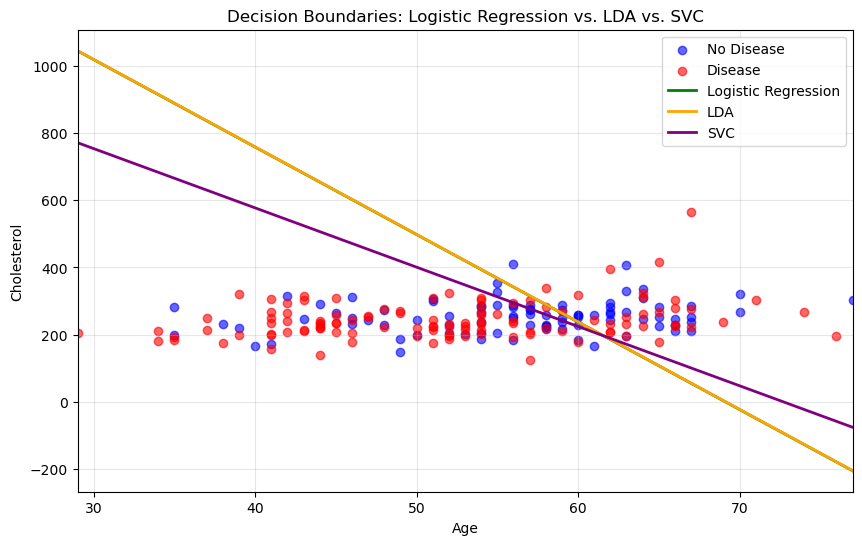

In [8]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

for diagnosis, color in [(0, "blue"), (1, "red")]:
    mask = y == diagnosis

    plt.scatter(
        X.loc[mask, "age"],
        X.loc[mask, "chol"],
        color=color,
        alpha=0.6,
        label="Disease" if diagnosis == 1 else "No Disease"
    )


age_range = np.linspace(X["age"].min(), X["age"].max(), 200)

# Logistic Regression
log_chol = -(logmod.intercept_[0] +
             logmod.coef_[0, 0] * age_range) / logmod.coef_[0, 1]

# LDA
lda_chol = -(lda.intercept_[0] +
             lda.coef_[0, 0] * age_range) / lda.coef_[0, 1]


# Extract tuned SVC and scaler
svc = best_model.named_steps["svc"]
scaler = best_model.named_steps["scaler"]

# Standardize age
age_scaled = (age_range - scaler.mean_[0]) / scaler.scale_[0]

# Calculate boundary in standardized cholesterol units
svc_chol_scaled = -(svc.intercept_[0] +
                    svc.coef_[0, 0] * age_scaled) / svc.coef_[0, 1]

# Convert cholesterol back to original units
svc_chol = svc_chol_scaled * scaler.scale_[1] + scaler.mean_[1]


plt.plot(age_range, log_chol,
         color="green", linewidth=2, label="Logistic Regression")

plt.plot(age_range, lda_chol,
         color="orange", linewidth=2, label="LDA")

plt.plot(age_range, svc_chol,
         color="purple", linewidth=2, label="SVC")

plt.xlabel("Age")
plt.ylabel("Cholesterol")
plt.title("Decision Boundaries: Logistic Regression vs. LDA vs. SVC")
plt.legend()
plt.grid(alpha=0.3)

# Keep the graph focused on the observed data
plt.xlim(X["age"].min(), X["age"].max())

plt.show()